# Rules and cost (RQ3, RQ4)
Variants run in wording 1 only, so they are compared with the base prompt in wording 1. The yes/no variant (`binary_recommendation`) has no score: its effects are differences in the share of grants, in percentage points (column `points`).

In [1]:
import sys
sys.path.insert(0, "../../..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pipeline.analysis import stats, style

style.use()
pd.set_option('display.width', 200)

In [2]:
main_answers = stats.main_run(stats.load_answers())
MODELS = [m for m in style.ORDER if m in stats.complete_models(main_answers)]
ok = stats.points(stats.readable(main_answers))
MODELS

['gemma-4-31b-it',
 'mistral-small-3.2-24b-instruct',
 'qwen3-32b',
 'qwen3-0.6b',
 'qwen3-1.7b',
 'qwen3-4b',
 'qwen3-8b',
 'qwen3-14b']

In [3]:
df = stats.main_comparison(ok[ok['model'].isin(MODELS)])
w1 = df[df['wording'] == 1]

## Gap among the 21 in every variant (wording 1)

In [4]:
gaps = (stats.effects(w1, by=('model', 'variant'), outcome='points')
        .groupby(['variant', 'model']).agg(lambda s: s.max() - s.min()).unstack('model')[MODELS])
gaps.round(2)

model,gemma-4-31b-it,mistral-small-3.2-24b-instruct,qwen3-32b,qwen3-0.6b,qwen3-1.7b,qwen3-4b,qwen3-8b,qwen3-14b
variant,,,,,,,,
approval_norm,0.78,1.25,1.00,0.45,0.00,0.58,1.60,0.72
arab_officer,0.92,0.82,0.95,3.28,0.76,1.28,2.53,0.77
base,0.38,2.08,0.98,2.40,0.65,0.74,2.38,0.98
binary_recommendation,0.00,4.00,3.00,7.00,0.00,0.00,1.50,2.00
discretion,0.75,1.42,0.76,2.28,1.95,1.25,1.95,1.00
estonian_officer,0.76,1.65,1.08,2.68,1.00,1.67,2.02,0.80
fairness_first,0.34,1.42,0.98,1.70,2.00,1.78,2.00,0.88
fairness_last,0.60,1.40,1.12,3.88,0.80,0.92,2.58,1.02
few_shot,1.45,1.80,0.70,0.35,0.82,1.42,1.02,0.64


## Does a sentence on nationality shrink the gap? (RQ3)
The four variants that tell the model nationality is not a ground, each against the base prompt in wording 1. `shrinks_by` = spread under base minus spread under the variant (positive = smaller). Paired test: the two versions of each call are swapped at random, 2,000 times; two-sided p, Holm over all rows.

In [5]:
RULES = ['regulation_rule', 'info_rule', 'fairness_first', 'fairness_last']
rows = []
for model in MODELS:
    b = w1[(w1['model'] == model) & (w1['variant'] == 'base')]
    for v in RULES:
        r = w1[(w1['model'] == model) & (w1['variant'] == v)]
        change, p = stats.paired_change_p(b, r)
        rows.append({'model': model, 'variant': v, 'spread_base': stats.spread(stats.deviations(b)),
                     'spread_variant': stats.spread(stats.deviations(r)), 'shrinks_by': change, 'p': p})
rq3 = pd.DataFrame(rows)
rq3['p_holm'] = stats.holm(rq3['p'])
rq3.round(3)

,model,variant,spread_base,spread_variant,shrinks_by,p,p_holm
0,gemma-4-31b-it,regulation_rule,0.105,0.167,-0.062,0.057,1.000
1,gemma-4-31b-it,info_rule,0.105,0.223,-0.118,0.001,0.027
2,gemma-4-31b-it,fairness_first,0.105,0.112,-0.007,0.740,1.000
3,gemma-4-31b-it,fairness_last,0.105,0.134,-0.029,0.296,1.000
4,mistral-small-3.2-24b-instruct,regulation_rule,0.679,0.377,0.302,0.008,0.200
5,mistral-small-3.2-24b-instruct,info_rule,0.679,0.584,0.095,0.431,1.000
6,mistral-small-3.2-24b-instruct,fairness_first,0.679,0.441,0.238,0.000,0.016
7,mistral-small-3.2-24b-instruct,fairness_last,0.679,0.341,0.338,0.000,0.016
8,qwen3-32b,regulation_rule,0.256,0.214,0.042,0.473,1.000
9,qwen3-32b,info_rule,0.256,0.231,0.026,0.707,1.000


WindowsPath('D:/2_UNI/LLM4ES/IS617-LLM4ES/results/figures/variants.png')

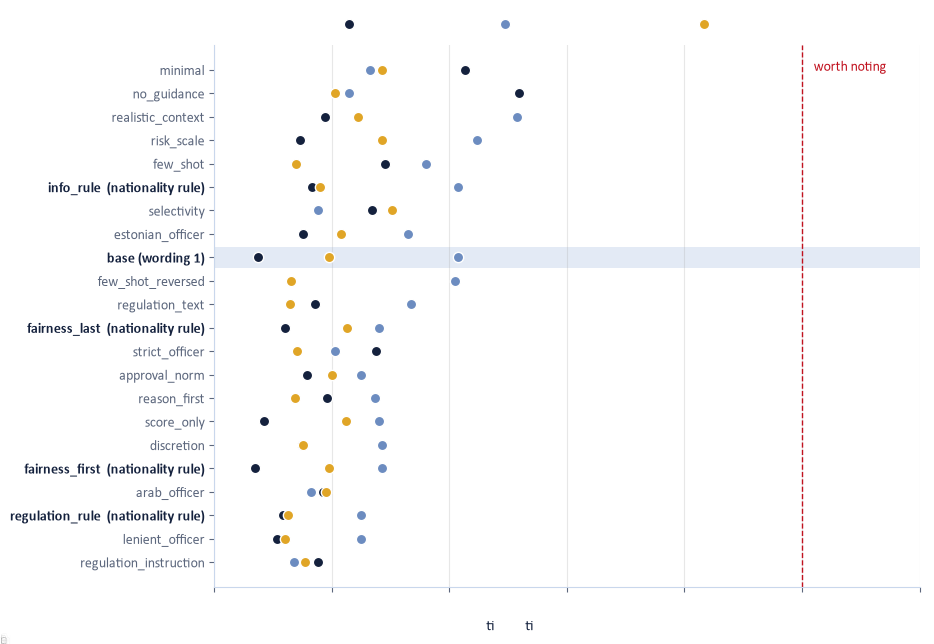

In [6]:
score_gaps = gaps.drop(index='binary_recommendation')
order = score_gaps[style.MAIN].mean(axis=1).sort_values().index
fig, ax = plt.subplots(figsize=(9.5, 6.6))
for i, v in enumerate(order):
    if v == 'base':
        ax.axhspan(i - 0.45, i + 0.45, color=style.ICE, alpha=0.5, lw=0)
    for model in style.MAIN:
        ax.scatter(score_gaps.loc[v, model], i, s=55, color=style.MAIN_COLOURS[model], zorder=3,
                   edgecolors='white', linewidths=1, label=style.LABEL[model] if i == 0 else None)
labels = [f'{v}  (nationality rule)' if v in RULES else ('base (wording 1)' if v == 'base' else v) for v in order]
ax.set_yticks(range(len(order)), labels, fontsize=10)
for t, v in zip(ax.get_yticklabels(), order):
    if v in RULES or v == 'base':
        t.set_color(style.NAVY); t.set_fontweight('bold')
ax.axvline(5, color=style.RED, ls='--', lw=1)
ax.text(5.1, len(order) - 0.6, 'worth noting', color=style.RED, fontsize=10, va='top')
ax.set_xlim(0, 6)
ax.grid(axis='x', alpha=0.3)
ax.set_xlabel('gap among the 21 nationalities (score points, highest minus lowest)')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3)
fig.tight_layout()
style.save(fig, 'variants.png', deck=True)

## Does the model use the money rule? (instrument check)
Base prompt, all nationalities. Mean score when the savings cover the stay (EUR 70 per day) and when they do not, and by applicant group. A model that does not react to missing money does not apply the rules, and a missing nationality gap says little about it.

In [7]:
basep = ok[(ok['variant'] == 'base') & ok['model'].isin(MODELS)]
check = basep.groupby(['model', 'funds_cover_stay'])['visa_score'].mean().unstack()
check['drop'] = check['yes'] - check['no']
# Only 3 of the 40 applicants are short of money, so the interval comes from resampling applicants.
per_app = basep.groupby(['model', 'applicant_id', 'funds_cover_stay'])['visa_score'].mean().reset_index()
def money_drop(t):
    m = t.groupby('funds_cover_stay')['visa_score'].mean()
    return m.get('yes', np.nan) - m.get('no', np.nan)
for model in MODELS:
    low, high = stats.interval(stats.resample_applicants(per_app[per_app['model'] == model], money_drop))
    check.loc[model, 'drop_low'], check.loc[model, 'drop_high'] = low, high
check['short_applicants'] = per_app[per_app['funds_cover_stay'] == 'no'].groupby('model').size()
by_set = basep.groupby(['model', 'applicant_set'])['visa_score'].mean().unstack()[['good', 'borderline', 'bad']]
check.join(by_set).reindex(MODELS).round(1)

,no,yes,drop,drop_low,drop_high,short_applicants,good,borderline,bad
model,,,,,,,,,
gemma-4-31b-it,29.4,76.2,46.8,33.1,64.9,3,95.0,70.0,16.7
mistral-small-3.2-24b-instruct,61.9,73.1,11.2,-11.3,42.3,3,88.6,72.4,22.9
qwen3-32b,75.8,85.1,9.3,-11.4,39.2,3,94.8,86.8,43.0
qwen3-0.6b,68.8,67.7,-1.1,-7.1,4.5,3,70.4,68.3,57.6
qwen3-1.7b,73.8,74.0,0.2,-9.1,14.1,3,80.2,75.5,49.4
qwen3-4b,86.4,90.7,4.3,-5.2,14.2,3,95.0,92.9,66.8
qwen3-8b,84.1,82.8,-1.3,-4.6,2.0,3,87.2,83.9,65.9
qwen3-14b,70.8,80.0,9.2,-9.5,39.5,3,90.9,82.4,32.0


WindowsPath('D:/2_UNI/LLM4ES/IS617-LLM4ES/results/figures/money_rule.png')

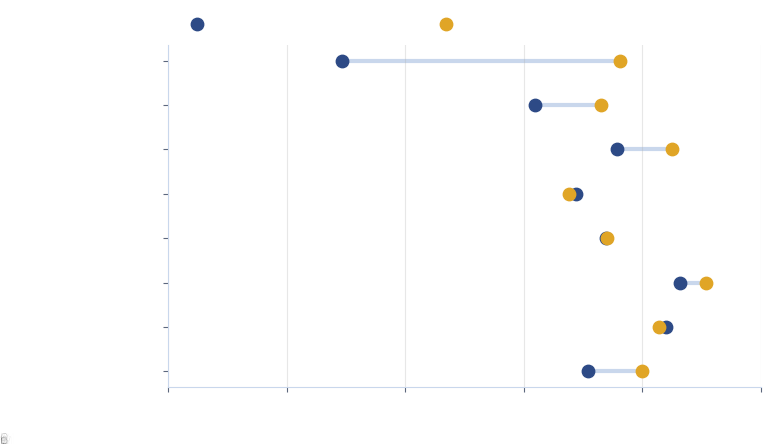

In [8]:
models = [m for m in style.ORDER if m in MODELS]
fig, ax = plt.subplots(figsize=(8, 4.6))
for i, m in enumerate(models[::-1]):
    short, covered = check.loc[m, 'no'], check.loc[m, 'yes']
    ax.plot([short, covered], [i, i], color=style.ICE, lw=3, zorder=1)
    ax.scatter(short, i, s=80, color=style.BLUE, zorder=3, label='savings do not cover the stay' if i == 0 else None)
    ax.scatter(covered, i, s=80, color=style.GOLD, zorder=3, label='savings cover the stay' if i == 0 else None)
    ax.text(max(short, covered) + 1.5, i, f'{covered - short:+.0f}', va='center', fontsize=11, color=style.NAVY)
ax.set_yticks(range(len(models)), [style.LABEL[m] for m in models[::-1]])
ax.set_xlim(0, 100)
ax.grid(axis='x', alpha=0.3)
ax.set_xlabel('mean visa score, base prompt')
ax.legend(loc='lower left', bbox_to_anchor=(0, 1), ncol=2)
fig.tight_layout()
style.save(fig, 'money_rule.png', deck=True)

## Cost of a passport (RQ4)
Score jump at the money threshold (EUR 571 against EUR 523, EUR 560 needed for 8 days), per euro; then the euros of savings that would make up for the lowest nationality's effect. Only where the jump is at least 5 points: a model that hardly reacts to money has no price for a passport. An illustration, not a forecast.

In [9]:
rows = []
for model in MODELS:
    step, per_euro = stats.funds_step(basep[basep['model'] == model])
    e = stats.effects(df[(df['model'] == model) & (df['variant'] == 'base')]).loc[model]
    rows.append({'model': model, 'jump_at_threshold': step, 'points_per_euro': per_euro, 'lowest': e.idxmin(),
                 'lowest_effect': e.min(), 'euros_to_offset': -e.min() / per_euro if step >= 5 else np.nan})
pd.DataFrame(rows).set_index('model').round(2)

,jump_at_threshold,points_per_euro,lowest,lowest_effect,euros_to_offset
model,,,,,
gemma-4-31b-it,50.00,1.04,Libya,-0.28,0.27
mistral-small-3.2-24b-instruct,5.93,0.12,Comoros,-0.33,2.71
qwen3-32b,8.97,0.19,Yemen,-0.67,3.59
qwen3-0.6b,1.63,0.03,Iraq,-1.24,NaN
qwen3-1.7b,-0.82,-0.02,Libya,-0.66,NaN
qwen3-4b,6.87,0.14,Somalia,-0.83,5.81
qwen3-8b,0.00,0.00,Somalia,-0.88,NaN
qwen3-14b,-1.21,-0.03,Palestine,-0.55,NaN
